# Quality Control of AFM Force Spectroscopy Data using Simulation Data

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
<a href="https://colab.research.google.com/github/JChonpca/ASAP/blob/AD/tutorials/quality-control/QC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<strong>If using Colab/Kaggle:</strong> You need to uncomment the code in the cell below this one.
You also need to copy the "ae.py" file, "afm_simulation.py", and "models" folder from the
<a href="https://github.com/DeepTrackAI/ASAP/blob/main/tutorials/quality-control">notebook folder</a> in GitHub to the Colab/Kaggle work directory.
</div>

This notebook provides you with a complete code example that first trains multilayer perceptron (MLP) based filter to generate the denoised force curve based on the simulation data; then uses the reconstruction error to detect bad curves in the experimental data.

- **Output 1:** A trained model ready to process experimental data.
- **Output 2:** The weidget to determine threshold for reconstruction loss to identify the good/bad curves.

## 1. Imports and configuration

Here we import necessary libraries and scripts.

In [23]:
from __future__ import annotations

import glob
import importlib
import json
import logging
import os
import random
import sys
from copy import deepcopy
from typing import Optional
from pathlib import Path
import shutil

import matplotlib
import matplotlib.animation
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import torch
import torch.nn as nn

from scipy.interpolate import interp1d
from sklearn.metrics import mean_squared_error, root_mean_squared_error
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

import deeplay as dl
import lightning as L
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from pytorch_lightning.loggers import CSVLogger

We configure our simulator and model. The user must configure the experimental parameters, sample parameters and if desired the model parameters to adapt to their experimental setup.

1. **SimulationConfig**:
    1. The user must select the scan resolution that consists of pixel number $(n_x, n_y)$ and pixel size.
    2. Force-distance curve (FDC) parameters must be defined: $z~length$, $z~speed$, sampling frequency $f_s$ and $set-point~force$.
    3. Depending on the cantilever choice the tip shape and the desired thermal noise type must be selected.
    4. Curve mode must be selected between 'approach' and 'approach-retract'. This will depend on the used contact mechanics model.
3. **DatasetConfig**:
    1. Quantity of samples for training, validating and testing must be indicated.
    2. Topography types we want to use and the height range we are expecting.
    3. Range of stiffness for the substrate and the sample must be indicated. This is only an estimation and doesn't need to be precise.
5. **ModelConfig**:
    1. This contains the parameters of the model. The user does not need to adjust these values but it can b emodified if desired.

In [3]:
SEED = 70
np.random.seed(SEED)
torch.manual_seed(SEED)

from afm_simulation import (
    AFMCantilever,
    AFMSimulator,
    DatasetConfig,
    HertzContact,
    ModelConfig,
    SampleGenerator,
    SimulationConfig,
    dataset_config,
    model_config,
    simulation_config,
)

from afm_plotting import plot_force_curve, plot_maps, plot_psd

## 2. Instantiate the simulator and generate one example sample

Approach points = 1000
Setpoint force range = 1.00 - 1.00 nN


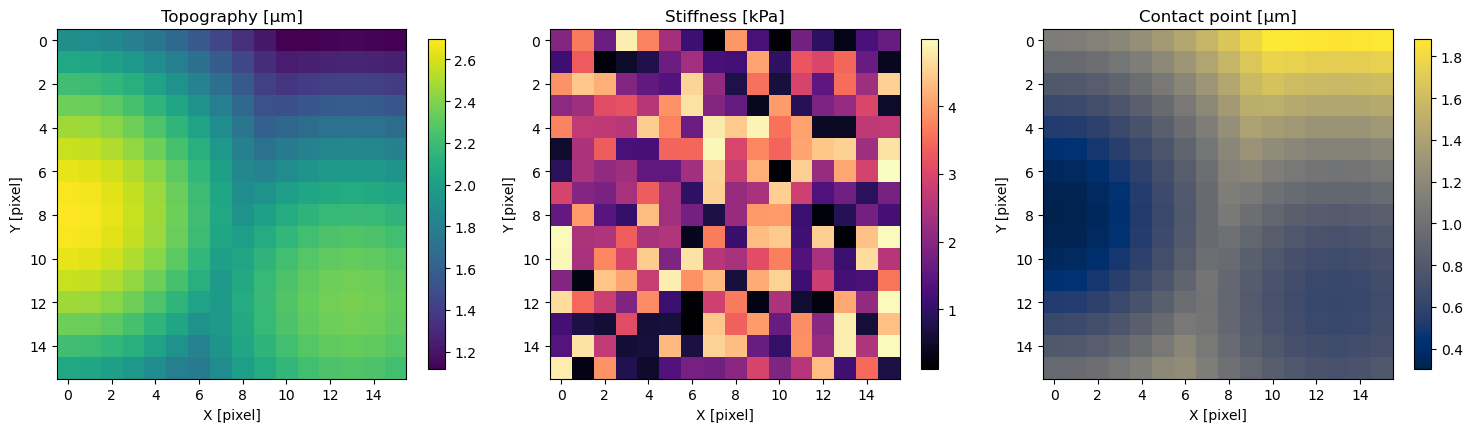

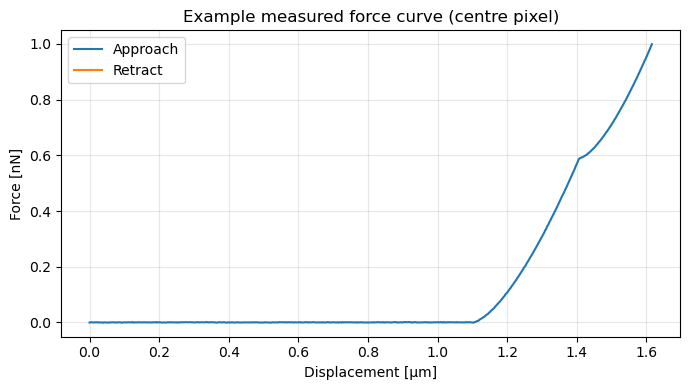

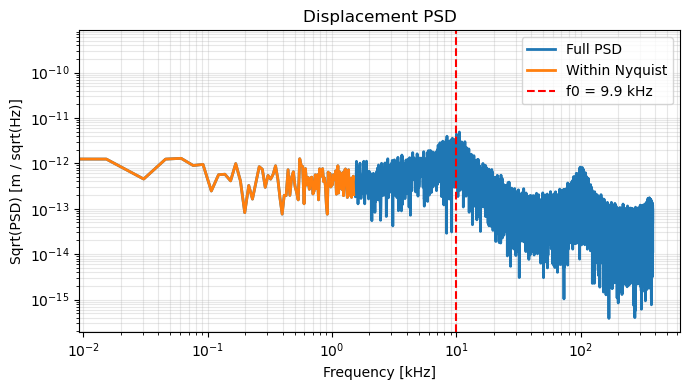

In [4]:
# We use the simulator to generate data and visualise it with the functions
# defined above.
rng = np.random.default_rng(SEED)

example_substrate_stiffness_range_pa = (0.1e3, 5e3)
example_feature_stiffness_range_pa = (0.1e3, 5e3)
example_nx = 16
example_ny = 16

example_stiffness_min_pa = min(example_substrate_stiffness_range_pa[0],
                               example_feature_stiffness_range_pa[0])
example_stiffness_max_pa = max(example_substrate_stiffness_range_pa[1],
                               example_feature_stiffness_range_pa[1])

cantilever = AFMCantilever(k=0.178, f0=10e3, Q=100.0, T=300.0)
contact_model = HertzContact(R=1e-6, nu=0.5, alpha=18.0)
sample_generator = SampleGenerator(
    substrate_stiffness_range_pa=example_substrate_stiffness_range_pa,
    feature_stiffness_range_pa=example_feature_stiffness_range_pa,
    height_range_m=dataset_config.height_range_m
)
simulator = AFMSimulator(
    cantilever=cantilever,
    contact_model=contact_model,
    sample_generator=sample_generator,
    config=simulation_config,
)

print(f"Approach points = {simulator.n_points_approach}")
print(f"Setpoint force range = \
{min(simulation_config.setpoint_force_n_range) * 1e9:.2f} - \
{max(simulation_config.setpoint_force_n_range) * 1e9:.2f} nN")

example_topography_m, example_stiffness_pa = (
    sample_generator.create_topography(
        size=(example_nx, example_ny),
        pixel_size_m=simulation_config.pixel_size_m,
        topography_type="gaussian_features",
        rng=rng,
    )
)

example_output = simulator.simulate_force_map(
    stiffness_map_pa=example_stiffness_pa,
    topography_map_m=example_topography_m,
    include_thermal_noise=simulation_config.include_thermal_noise,
    rng=rng,
)

plot_maps(
    example_topography_m, 
    example_stiffness_pa, 
    example_output["contact_point_map_m"]
)

center_row = 0
center_col = 0
plot_force_curve(
    example_output["displacement_curves_m"][center_row, center_col],
    example_output["measured_force_curves_n"][center_row, center_col],
    retract_start_index= \
      int(example_output["retract_start_indices"][center_row, center_col]),
    valid_length=int(example_output["curve_lengths"][center_row, center_col]),
    title="Example measured force curve (centre pixel)",
)

reference_points = max(simulator.n_points_approach * 2, 64)
if simulation_config.noise_type == "rms":
    frequency_hz, spectral_density_m2_per_hz = cantilever.get_noise_psd(
        n_points=reference_points,
        sampling_frequency_hz=cantilever.f0*10,
        noise_type="theoretical",
        experimental_path=simulation_config.experimental_noise_path,
    )

else:
    frequency_hz, spectral_density_m2_per_hz = cantilever.get_noise_psd(
        n_points=reference_points,
        sampling_frequency_hz=cantilever.f0*10,
        noise_type=simulation_config.noise_type,
        experimental_path=simulation_config.experimental_noise_path,
    )
plot_psd(
    frequency_hz,
    spectral_density_m2_per_hz,
    cantilever,
    sampling_frequency=simulation_config.sampling_frequency_hz,
)


## 3. Curve Generation and Preprocessing

Generate the curves and interpolate the tip displament and measured force to fix length ...

In [8]:
align_length = 1500

rng = np.random.default_rng(577)
ny = 1
nx = 1

stiffness_range_min = \
min(simulator.sample_generator.substrate_stiffness_range_pa[0], \
    simulator.sample_generator.feature_stiffness_range_pa[0])
stiffness_range_max = \
max(simulator.sample_generator.substrate_stiffness_range_pa[1], \
    simulator.sample_generator.feature_stiffness_range_pa[1])

def preprocess_synthetic_data(
    output: dict,
    align_length: int,
)-> tuple[np.ndarray, np.ndarray]:
    """Preprocess synthetic AFM data for denosing.

    Parameters
    ----------
    output: dict
        Output from the AFMSimulator containing force curves and metadata.
    align_length: int
        Length to which all curves will be aligned (via interpolation).

    Returns
    -------
    tuple[np.ndarray, np.ndarray]
        Tuple of (data_x, data_y) where data_x contains the aligned force
        curves and data_y contains the corresponding denoised curve.

    """

    ny = output["curve_lengths"].shape[0]
    nx = output["curve_lengths"].shape[1]

    n_total = ny * nx
    data_x = np.empty((n_total, align_length), dtype=np.float32) 
    data_y = np.empty((n_total, align_length), dtype=np.float32)
    idx = 0

    for r in range(ny):
        for c in range(nx):
            deno_all = output["force_curves_n"][r, c]
            deno_all = np.asarray(deno_all, dtype=np.float64)

            meas_all = output["measured_force_curves_n"][r, c]
            meas_all = np.asarray(meas_all, dtype=np.float64)

            no_all = meas_all - deno_all

            if random.random() < 0.9:
                meas_all = deno_all + no_all*random.random()
            else:
                meas_alll = deno_all

            x_old = np.linspace(0, 1, meas_all.size)
            x_new = np.linspace(0, 1, align_length)

            deno = np.interp(x_new, x_old, deno_all)*1e9
            meas = np.interp(x_new, x_old, meas_all)*1e9

            min_force = min(deno.min(), meas.min())
            max_force = max(deno.max(), meas.max())

            deno = (deno - min_force)/(max_force - min_force + 1e-9)
            meas = (meas - min_force)/(max_force - min_force + 1e-9)

            data_x[idx] = meas
            data_y[idx] = deno
            idx += 1


    return data_x, data_y

n_total = 10000 * nx * ny
data_x_r = np.empty((n_total, align_length), dtype=np.float32)
data_y_r = np.empty((n_total, align_length), dtype=np.float32)
idx = 0
for i in range(n_total):
    topography_type = rng.choice(dataset_config.topography_types)
    topo_m, stiff_pa = sample_generator.create_topography(
        size=(ny, nx),
        pixel_size_m=simulator.config.pixel_size_m,
        topography_type=topography_type,
        rng=rng,
    )
    out = simulator.simulate_force_map(
        stiffness_map_pa=stiff_pa,
        topography_map_m=topo_m,
        include_thermal_noise=simulator.config.include_thermal_noise,
        noise_type=simulator.config.noise_type,
        experimental_path=simulator.config.experimental_noise_path,
        rng=rng,
    )

    data_x_i, data_y_i = preprocess_synthetic_data(
        out,
        align_length,
    )

    data_x_r[idx : idx + data_x_i.shape[0]] = data_x_i
    data_y_r[idx : idx + data_y_i.shape[0]] = data_y_i
    idx += data_x_i.shape[0]

    del out, topo_m, stiff_pa


print(f"Final dataset shape: data_x={data_x_r.shape}, data_y={data_y_r.shape}")

Final dataset shape: data_x=(10000, 1500), data_y=(10000, 1500)


... plot some simulated curves and corresponding reconstructed one ...

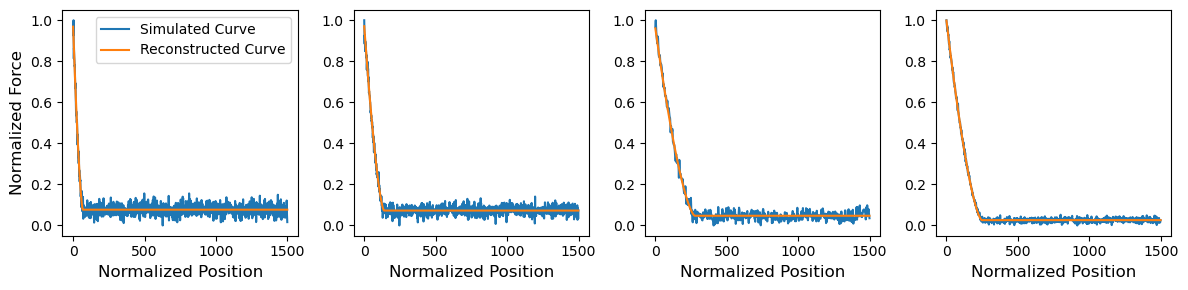

In [37]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 4, figsize=((12, 3)))

for curve_idx, ax in enumerate(axs.ravel()):
    simulated_curve = data_x_r[curve_idx][::-1]
    reconstructed_curve = data_y_r[curve_idx][::-1]

    ax.plot(simulated_curve, label="Simulated Curve")
    ax.plot(reconstructed_curve, label="Reconstructed Curve")


    ax.set_xlabel("Normalized Position", fontsize=12)
    if curve_idx == 0:
        ax.set_ylabel("Normalized Force", fontsize=12)
        ax.legend()

fig.tight_layout()
plt.show()

... and create the dataloader for tranining.

In [14]:
(
    curves_x_train,
    curves_x_test,
    curves_y_train,
    curves_y_test,
) = train_test_split(
    data_x_r,
    data_y_r,
    test_size=0.2,
    random_state=577,
)


# Transfer them to Torch.Tensor

train_x = torch.as_tensor(curves_x_train, dtype=torch.float32)
train_y = torch.as_tensor(curves_y_train, dtype=torch.float32)


test_x = torch.as_tensor(curves_x_test, dtype=torch.float32)
test_y = torch.as_tensor(curves_y_test, dtype=torch.float32)


# Instantiate the dataloader for train data
train_dataloader = dl.DataLoader(
    TensorDataset(train_x, train_x),
    batch_size=40960, shuffle=True
)

# Instantiate the dataloader for test data
test_dataloader = dl.DataLoader(
    TensorDataset(test_x, test_x),
    batch_size=40960, shuffle=True
)

## 4. MLP Training

Import the conditional variational autoencoder module and instantiate a AE with dense layers ...

In [5]:
from ae import AutoEncoder

min_approach_curve_length = 1500

# Instantiate the cAE model according to the data properties
ae = AutoEncoder(
    input_size=min_approach_curve_length,
    channels=[512, 256, 128, 64],
    reconstruction_loss=torch.nn.MSELoss(reduction="mean"),
    latent_dim=2,
)

# Configure the activated function
ae.encoder.blocks[:].activated(torch.nn.Tanh)
ae.decoder.blocks[:4].activated(torch.nn.Tanh)
ae.decoder.blocks[4].activated(torch.nn.Sigmoid)

# Create the AE application
ae = ae.create()

print(ae)

AutoEncoder(
  (encoder): MultiLayerPerceptron(
    (blocks): LayerList(
      (0): LinearBlock(
        (layer): Linear(in_features=1500, out_features=512, bias=True)
        (activation): Tanh()
      )
      (1): LinearBlock(
        (layer): Linear(in_features=512, out_features=256, bias=True)
        (activation): Tanh()
      )
      (2): LinearBlock(
        (layer): Linear(in_features=256, out_features=128, bias=True)
        (activation): Tanh()
      )
      (3): LinearBlock(
        (layer): Linear(in_features=128, out_features=64, bias=True)
        (activation): Tanh()
      )
      (4): LinearBlock(
        (layer): Linear(in_features=64, out_features=64, bias=True)
        (activation): Tanh()
      )
    )
  )
  (fc_enc): Linear(in_features=64, out_features=2, bias=True)
  (fc_dec): Linear(in_features=2, out_features=64, bias=True)
  (decoder): MultiLayerPerceptron(
    (blocks): LayerList(
      (0): LinearBlock(
        (layer): Linear(in_features=64, out_features=64,

... and instance a trainer with a callback to monitor the validation loss and save the best model ...

In [6]:
from lightning.pytorch.callbacks import ModelCheckpoint
from pytorch_lightning.loggers import CSVLogger

# Save the top-1 model according to the validation loss
checkpoint_callback = ModelCheckpoint(
    monitor="val_total_loss",
    mode="min",
    save_top_k=1,
)

# Set the logger
csv_logger = CSVLogger("logs")

# Instantiate the trainer
ae_trainer = dl.Trainer(
    max_epochs=5_000,
    accelerator="auto",
    callbacks=[checkpoint_callback],
    logger=csv_logger,
    enable_progress_bar=False,
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


... train the AE ...

In [10]:
ae_trainer.fit(ae, train_dataloader, test_dataloader)

You are using a CUDA device ('NVIDIA A100-PCIE-40GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


┏━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                ┃ Type                 ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder             │ MultiLayerPerceptron │  945 K │ train │     0 │
│ 1 │ fc_enc              │ Linear               │    130 │ train │     0 │
│ 2 │ fc_dec              │ Linear               │    192 │ train │     0 │
│ 3 │ decoder             │ MultiLayerPerceptron │  946 K │ train │     0 │
│ 4 │ reconstruction_loss │ MSELoss              │      0 │ train │     0 │
│ 5 │ train_metrics       │ MetricCollection     │      0 │ train │     0 │
│ 6 │ val_metrics         │ MetricCollection     │      0 │ train │     0 │
│ 7 │ test_metrics        │ MetricCollection     │      0 │ train │     0 │
│ 8 │ optimizer           │ Adam                 │      0 │ train │     0 │
└───┴─────────────────────┴──────────────────────┴────────┴───────┴───────┘

Trainable params: 1.9 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 1.9 M                                                                                                
Total estimated model params size (MB): 7.568                                                                      
Modules in train mode: 41                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

/opt/conda/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/conda/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:485: Your `val_dataloader`'s sampler has shuffling enabled, it is strongly recommended that you turn shuffling off for val/test dataloaders.
/opt/conda/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.
/opt/conda/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the

... and load the best model from the callback function.

In [11]:
print(f"The best model is saved at {checkpoint_callback.best_model_path}")

best_ae = AutoEncoder.load_from_checkpoint(
    checkpoint_callback.best_model_path
)

The best model is saved at logs/lightning_logs/version_32/checkpoints/epoch=4999-step=5000.ckpt


You can also load a pretrained model by uncommenting the code below.

In [17]:
# Uncomment if you want to load a pretrained model

# pretraiend_model_path = Path.cwd() / "models" / "epoch=4999-step=5000.ckpt"

# print(f"Loading the model at {pretraiend_model_path}")

# ae.load_state_dict(
#    torch.load(pretraiend_model_path, map_location="cpu")["state_dict"]
# )
# best_ae = ae


Loading the model at /asap/models/epoch=4999-step=5000.ckpt


Evaluate the trained AE using both the train dataset ...

In [21]:
# Evaluate performance of trained AE on train dataset

_ = ae_trainer.test(best_ae, train_dataloader)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│   test_total_loss_epoch   │   0.000385769410058856    │
└───────────────────────────┴───────────────────────────┘

... and on the test dataset.

In [22]:
# Evaluate performance of trained AE on test dataset

_ = ae_trainer.test(best_ae, test_dataloader)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│   test_total_loss_epoch   │   0.0004210459883324802   │
└───────────────────────────┴───────────────────────────┘

## 5. Evaluation in the 3T3 cell dataset

Download the 3T3_cell_dataset into the `3T3_cell_dataset` local folder ...

In [27]:
if not os.path.exists("3t3_cell_dataset"):
    os.system("git clone https://github.com/DeepTrackAI/3t3_cell_dataset")

... and load with preprocessing to be compatible with the filter.

In [30]:
# Load the approach curves
approach_path = Path.cwd() / "3t3_cell_dataset" / "approach"
approach_files = sorted(approach_path.glob("*.npy"), key=lambda f: int(f.stem))
approach_curves = [np.load(f) for f in approach_files]

# Load the retraction curves
retract_path = Path.cwd() / "3t3_cell_dataset" / "retraction"
retract_files = sorted(retract_path.glob("*.npy"), key=lambda f: int(f.stem))
retract_curves = [np.load(f) for f in retract_files]

# Load the labels
labels = np.load(Path.cwd() / "3t3_cell_dataset" / "label.npy")

# Load the contact points
contactpoints = np.load(Path.cwd() / "3t3_cell_dataset" / "contact_point.npy")




def label_separate(labels: np.ndarray[int], 
                   label: int, 
                   *arrays: np.ndarray,
) -> tuple[list, ...]:
    """Separates data based on a specified label.

    This utility function filters multiple aligned NumPy arrays according
    to a given label. It returns subsets of the input arrays where the
    labels match the specified value.

    Parameters
    ----------
    labels : np.ndarray[int]
        Array of labels used for filtering.
    label : int
        Target label to select.
    *arrays : np.ndarray
        One or more NumPy arrays aligned with `labels`. All arrays must
        have the same length as `labels`.

    Returns
    -------
    tuple[list, ...]
        A tuple where each element corresponds to a filtered version of
        the input arrays, containing only elements whose label matches
        the specified value.

    Examples
    --------
    >>> labels = np.array([0, 0, 1, 1, 1])
    >>> label = 1
    >>> list1 = np.array([1, 2, 3, 4, 5])
    >>> list2 = np.array([5, 4, 3, 2, 1])
    >>> s_l1, s_l2 = label_separate(labels, label, list1, list2)
    >>> s_l1, s_l2
    ([3, 4, 5], [3, 2, 1])

    """

    idx = np.where(labels == label)[0]
    return tuple([[arr[i] for i in idx] for arr in arrays])



# Calculate the length of each curve
approach_curve_lengths = [curve.shape[0] for curve in approach_curves]
retract_curve_lengths = [curve.shape[0] for curve in retract_curves]

# Calculate the minimum length of approach curves and retraction curves
min_approach_curve_length = align_length
min_retract_curve_length = align_length

resampled_approach_curves = []
resampled_contactpoints = []
for approach_curve, contactpoint in zip(approach_curves, contactpoints):
    # Resample each approach curve to adjust its length to the shortest one
    steps = np.round(
        np.linspace(0, approach_curve.shape[0] - 1, min_approach_curve_length)
    ).astype(int)
    resampled_approach_curve = approach_curve[steps][:, 1]
    resampled_approach_curves.append(resampled_approach_curve)

    # Determine the contact point for the resampled approach curve
    resampled_approach_position = approach_curve[steps][:, 0]
    resampled_contactpoint = (
        np.abs(resampled_approach_position - contactpoint).argmin()
    )
    resampled_contactpoints.append(resampled_contactpoint)

    norm_approach_curves = []
    
    for resampled_approach_curve in resampled_approach_curves:
        norm_approach_curves.append(
            (resampled_approach_curve - resampled_approach_curve.min())
            / (resampled_approach_curve.max() - resampled_approach_curve.min())
        )
    
    # Normalize each contact point according to min approach length
    norm_contact_points = []
    
    for resampled_contactpoint in resampled_contactpoints:
        norm_contact_points.append(
            resampled_contactpoint / min_approach_curve_length
        )

The trained filter can be used to reconstruct and denoise the approach curves ...

In [31]:
# Put the model under eval mode
best_ae.eval()

# Construct the dataset
norm_approach_curves = torch.as_tensor(
    norm_approach_curves, 
    dtype=torch.float32
)

all_dataloader = dl.DataLoader(
    TensorDataset(norm_approach_curves, norm_approach_curves),
    batch_size=len(norm_approach_curves),
    shuffle=False
)

# Collect the original curves and corresponding reconstruction
with torch.no_grad():
    for indx, batch in enumerate(all_dataloader):
        x_list, y_list = batch
        y_hat_list, _, = best_ae(x_list)

# Transfer them into Numpy array
y_list = x_list.numpy()
y_hat_list = y_hat_list.numpy()

# Extract the good curves and corresponding reconstruction
(
    good_curves,
    good_reconstructions,
) = label_separate(
    labels,
    1,
    y_list,
    y_hat_list,
)

# Extract the good curves and corresponding reconstruction
(
    bad_curves,
    bad_reconstructions,
) = label_separate(
    labels,
    0,
    y_list,
    y_hat_list,
)

# Transfer them into Numpy array
(
    good_curves, 
    good_reconstructions, 
    bad_curves, 
    bad_reconstructions
) = (
    np.array(good_curves),
    np.array(good_reconstructions),
    np.array(bad_curves),
    np.array(bad_reconstructions),
)

/tmp/ipykernel_584/2079759120.py:5: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  norm_approach_curves = torch.as_tensor(


... visualize the comparison between raw curve and reconstructed one.

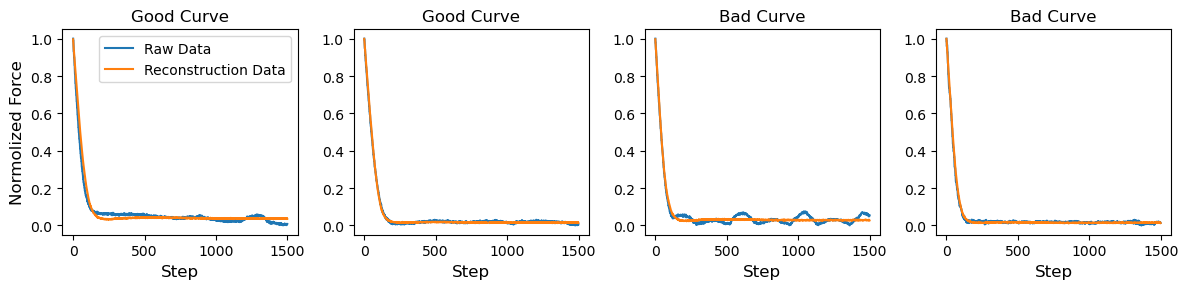

In [46]:
# Plot the comparison between the reconstruction and the originals
fig, axs = plt.subplots(1, 4, figsize=((12, 3)))

for curve_idx, ax in enumerate(axs.ravel()):
    if curve_idx < 2:
        # good curves part
        data_apporach_plot_raw = good_curves[curve_idx][::-1]
        data_apporach_plot_reconstruct = good_reconstructions[curve_idx][::-1]
        data_label = "Good Curve"
    else:
        # bad curves part
        data_apporach_plot_raw = bad_curves[curve_idx][::-1]
        data_apporach_plot_reconstruct = bad_reconstructions[curve_idx][::-1]
        data_label = "Bad Curve"
    
    ax.plot(data_apporach_plot_raw, label="Raw Data")
    ax.plot(data_apporach_plot_reconstruct, label="Reconstruction Data")

    ax.set_title(data_label)
    ax.set_xlabel("Step", fontsize=12)
    
    if curve_idx == 0:
        ax.set_ylabel("Normolized Force", fontsize=12)
        ax.legend()

fig.tight_layout()
plt.show()

Calculate the reconstructed loss ...

In [36]:
all_diff = abs(y_list[:,:] - y_hat_list[:,:]).mean(axis=1)

... and evaluate the classification performance using receiver operating characteristic (ROC) curve and precision-recall curves.

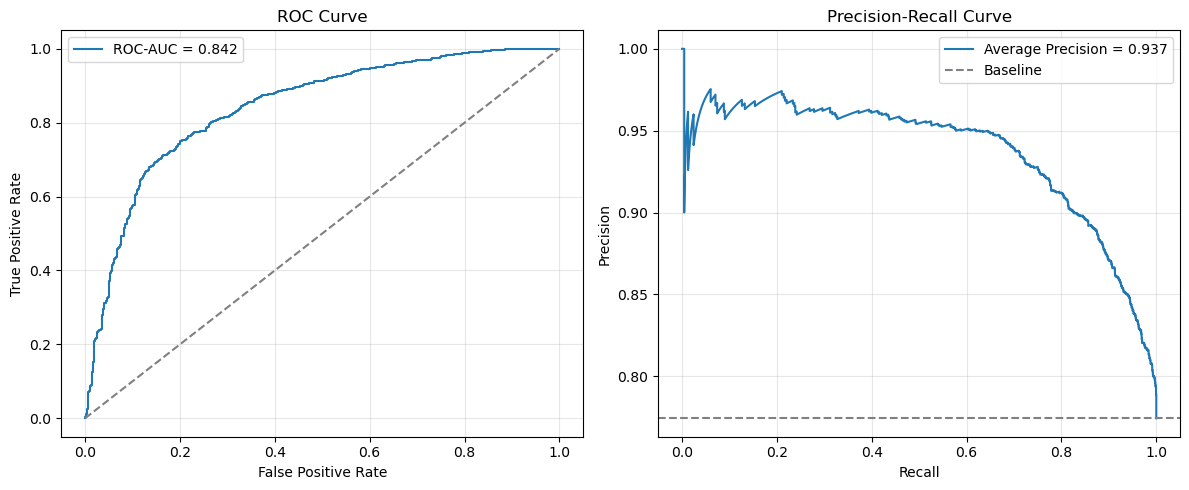

ROC-AUC = 0.842
Average Precision = 0.937


In [38]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc,
    average_precision_score,
    roc_auc_score
)

# Ground truth
y_true = np.where(labels == 2, 1, labels)

# Continuous reconstruction error as anomaly score
y_score = -all_diff

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr)

# PR curve
precision, recall, pr_thresholds = precision_recall_curve(
    y_true, y_score
)
ap = average_precision_score(y_true, y_score)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()
axes[0].grid(alpha=0.3)

# PR
axes[1].plot(recall, precision, label=f"Average Precision = {ap:.3f}")
axes[1].axhline(
    y_true.mean(),
    linestyle="--",
    color="gray",
    label="Baseline"
)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"ROC-AUC = {roc_auc:.3f}")
print(f"Average Precision = {ap:.3f}")

Pick up the threshold value manually with widget.

In [ ]:
import plotly.graph_objects as go

# Sort by reconstruction loss
sorted_idx = np.argsort(all_diff)
y_list_sort = [y_list[i][::-1] for i in sorted_idx]
y_hat_list_sort = [y_hat_list[i][::-1] for i in sorted_idx]
diff_sort = [all_diff[i] for i in sorted_idx]

# Frames Construction
frames = []
for i in range(len(y_list_sort)):
    frames.append(
        go.Frame(
            data=[
                go.Scatter(y=y_list_sort[i], mode="lines", name="Raw Data"),
                go.Scatter(y=y_hat_list_sort[i], mode="lines", name="Reconstruction Data"),
            ],
            name=str(i),
            layout=go.Layout(title=f"Reconstruction Loss={diff_sort[i]:.4f}"),
        )
    )

# Initial Picture
fig = go.Figure(
    data=[
        go.Scatter(y=y_list_sort[0], mode="lines", name="Raw Data"),
        go.Scatter(y=y_hat_list_sort[0], mode="lines", name="Reconstruction Data"),
    ],
    layout=go.Layout(title=f"Reconstruction Loss={diff_sort[0]:.4f}"),
    frames=frames,
)

# Slider
sliders = [
    {
        "steps": [
            {
                "args": [
                    [str(i)],
                    {"frame": {"duration": 0, "redraw": True}, "mode": "immediate"},
                ],
                "label": f"{i}",
                "method": "animate",
            }
            for i in range(len(y_list_sort))
        ],
        "currentvalue": {"prefix": "Index: "},
    }
]

fig.update_layout(sliders=sliders, autosize=False, width=700, height=500)

fig.show()

## 6. Evaluation in the Gel dataset

Download the gel_dataset into the `gel_dataset` local folder ...

In [42]:
if not os.path.exists("gel_dataset"):
    os.system("git clone https://github.com/DeepTrackAI/gel_dataset")

... and load with preprocessing to be compatible with the filter.

In [44]:
# Load the approach curves
approach_path = Path.cwd() / "gel_dataset" / "approach"
approach_files = sorted(approach_path.glob("*.npy"), key=lambda f: int(f.stem))
approach_curves = [np.load(f) for f in approach_files]

# Load the retraction curves
retract_path = Path.cwd() / "gel_dataset" / "retraction"
retract_files = sorted(retract_path.glob("*.npy"), key=lambda f: int(f.stem))
retract_curves = [np.load(f) for f in retract_files]

# Load the labels
labels = np.load(Path.cwd() / "gel_dataset" / "label.npy")

# Load the contact points
contactpoints = np.load(Path.cwd() / "gel_dataset" / "contact_point.npy")
young_modulus = np.load(Path.cwd() / "gel_dataset" / "young_modulus.npy")

# Calculate the length of each curve
approach_curve_lengths = [curve.shape[0] for curve in approach_curves]
retract_curve_lengths = [curve.shape[0] for curve in retract_curves]

# Calculate the minimum length of approach curves and retraction curves
min_approach_curve_length = align_length
min_retract_curve_length = align_length

resampled_approach_curves = []
resampled_contactpoints = []
for approach_curve, contactpoint in zip(approach_curves, contactpoints):
    # Resample each approach curve to adjust its length to the shortest one
    steps = np.round(
        np.linspace(0, approach_curve.shape[0] - 1, min_approach_curve_length)
    ).astype(int)
    resampled_approach_curve = approach_curve[steps][:, 1]
    resampled_approach_curves.append(resampled_approach_curve)

    # Determine the contact point for the resampled approach curve
    resampled_approach_position = approach_curve[steps][:, 0]
    resampled_contactpoint = (
        np.abs(resampled_approach_position - contactpoint).argmin()
    )
    resampled_contactpoints.append(resampled_contactpoint)

norm_approach_curves = []

for resampled_approach_curve in resampled_approach_curves:
    norm_approach_curves.append(
        (resampled_approach_curve - resampled_approach_curve.min())
        / (resampled_approach_curve.max() - resampled_approach_curve.min())
    )

# Normalize each contact point according to min approach length
norm_contact_points = []

for resampled_contactpoint in resampled_contactpoints:
    norm_contact_points.append(
        resampled_contactpoint / min_approach_curve_length
    )

The trained filter can be used to reconstruct and denoise the approach curves ...

In [45]:
# Put the model under eval mode
best_ae.eval()

# Construct the dataset
norm_approach_curves = torch.as_tensor(
    norm_approach_curves, 
    dtype=torch.float32
)

all_dataloader = dl.DataLoader(
    TensorDataset(norm_approach_curves, norm_approach_curves),
    batch_size=len(norm_approach_curves),
    shuffle=False
)

# Collect the original curves and corresponding reconstruction
with torch.no_grad():
    for indx, batch in enumerate(all_dataloader):
        x_list, y_list = batch
        y_hat_list, _, = best_ae(x_list)

# Transfer them into Numpy array
y_list = x_list.numpy()
y_hat_list = y_hat_list.numpy()

# Extract the good curves and corresponding reconstruction
(
    good_curves,
    good_reconstructions,
) = label_separate(
    labels,
    1,
    y_list,
    y_hat_list,
)

# Extract the good curves and corresponding reconstruction
(
    bad_curves,
    bad_reconstructions,
) = label_separate(
    labels,
    0,
    y_list,
    y_hat_list,
)

# Transfer them into Numpy array
(
    good_curves, 
    good_reconstructions, 
    bad_curves, 
    bad_reconstructions
) = (
    np.array(good_curves),
    np.array(good_reconstructions),
    np.array(bad_curves),
    np.array(bad_reconstructions),
)

... visualize the comparison between raw curve and reconstructed one.

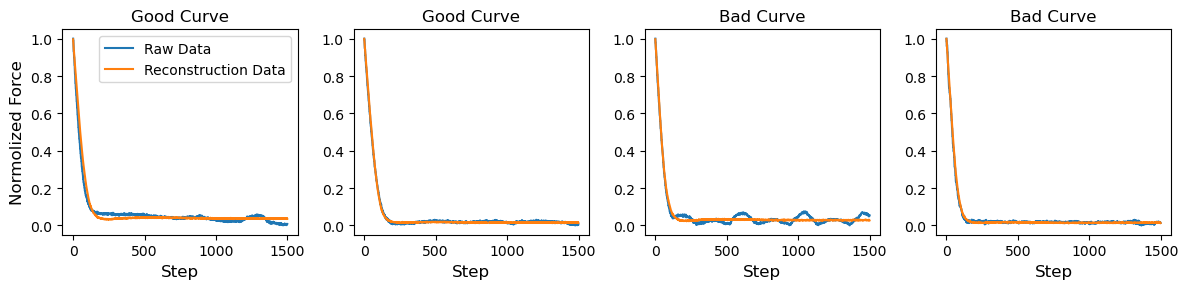

In [47]:
# Plot the comparison between the reconstruction and the originals
fig, axs = plt.subplots(1, 4, figsize=((12, 3)))

for curve_idx, ax in enumerate(axs.ravel()):
    if curve_idx < 2:
        # good curves part
        data_apporach_plot_raw = good_curves[curve_idx][::-1]
        data_apporach_plot_reconstruct = good_reconstructions[curve_idx][::-1]
        data_label = "Good Curve"
    else:
        # bad curves part
        data_apporach_plot_raw = bad_curves[curve_idx][::-1]
        data_apporach_plot_reconstruct = bad_reconstructions[curve_idx][::-1]
        data_label = "Bad Curve"
    
    ax.plot(data_apporach_plot_raw, label="Raw Data")
    ax.plot(data_apporach_plot_reconstruct, label="Reconstruction Data")

    ax.set_title(data_label)
    ax.set_xlabel("Step", fontsize=12)
    
    if curve_idx == 0:
        ax.set_ylabel("Normolized Force", fontsize=12)
        ax.legend()

fig.tight_layout()
plt.show()

Calculate the reconstructed loss ...

In [49]:
all_diff = abs(y_list[:,:] - y_hat_list[:,:]).mean(axis=1)

... and evaluate the classification performance using receiver operating characteristic (ROC) curve and precision-recall curves.

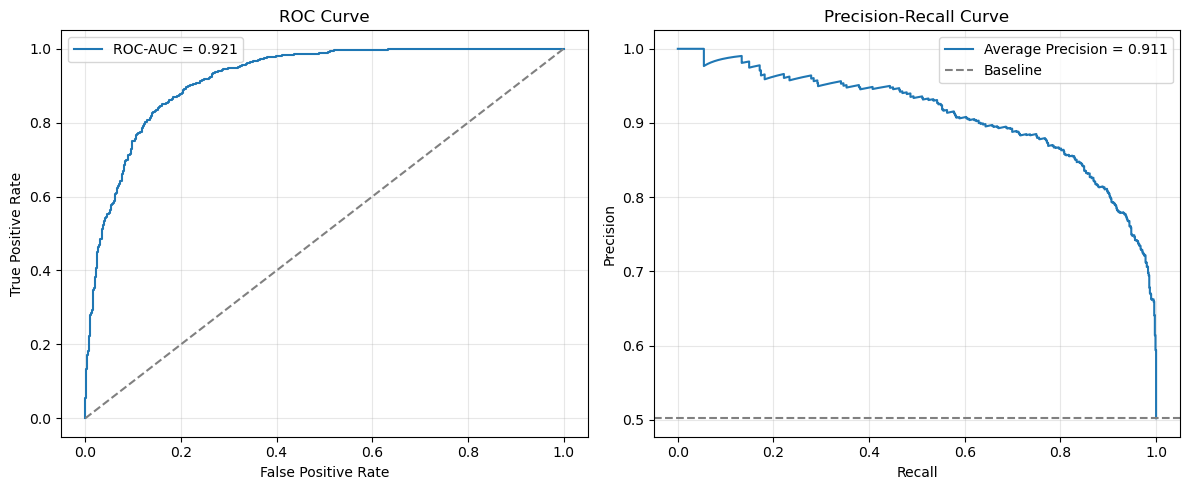

ROC-AUC = 0.921
Average Precision = 0.911


In [50]:
# Ground truth
y_true = np.where(labels == 2, 1, labels)

# Continuous reconstruction error as anomaly score
y_score = -all_diff

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr)

# PR curve
precision, recall, pr_thresholds = precision_recall_curve(
    y_true, y_score
)
ap = average_precision_score(y_true, y_score)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()
axes[0].grid(alpha=0.3)

# PR
axes[1].plot(recall, precision, label=f"Average Precision = {ap:.3f}")
axes[1].axhline(
    y_true.mean(),
    linestyle="--",
    color="gray",
    label="Baseline"
)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"ROC-AUC = {roc_auc:.3f}")
print(f"Average Precision = {ap:.3f}")

Pick up the threshold value manually with widget.

In [ ]:
# Sort by reconstruction loss
sorted_idx = np.argsort(all_diff)
y_list_sort = [y_list[i][::-1] for i in sorted_idx]
y_hat_list_sort = [y_hat_list[i][::-1] for i in sorted_idx]
diff_sort = [all_diff[i] for i in sorted_idx]

# Frames Construction
frames = []
for i in range(len(y_list_sort)):
    frames.append(
        go.Frame(
            data=[
                go.Scatter(y=y_list_sort[i], mode="lines", name="Raw Data"),
                go.Scatter(y=y_hat_list_sort[i], mode="lines", name="Reconstruction Data"),
            ],
            name=str(i),
            layout=go.Layout(title=f"Reconstruction Loss={diff_sort[i]:.4f}"),
        )
    )

# Initial Picture
fig = go.Figure(
    data=[
        go.Scatter(y=y_list_sort[0], mode="lines", name="Raw Data"),
        go.Scatter(y=y_hat_list_sort[0], mode="lines", name="Reconstruction Data"),
    ],
    layout=go.Layout(title=f"Reconstruction Loss={diff_sort[0]:.4f}"),
    frames=frames,
)

# Slider
sliders = [
    {
        "steps": [
            {
                "args": [
                    [str(i)],
                    {"frame": {"duration": 0, "redraw": True}, "mode": "immediate"},
                ],
                "label": f"{i}",
                "method": "animate",
            }
            for i in range(len(y_list_sort))
        ],
        "currentvalue": {"prefix": "Index: "},
    }
]

fig.update_layout(sliders=sliders, autosize=False, width=700, height=500)

fig.show()